# imports

In [1]:
import pandas as pd
import networkx as nx
from collections import defaultdict
import matplotlib.pyplot as plt
import numpy as np
from itertools import combinations
from collections import defaultdict

# Phase 1: Weighted disease–symptom bipartite graph

Prepare the disease and symptom data and represent the relationships as a weighted bipartite network.

# 1-create disease-symptom graph

## 1. Read the dataset

In [2]:
df = pd.read_csv("rawData.csv")

# . Strip whitespace and clean symptom values
symptom_cols = [col for col in df.columns if col.startswith('Symptom')]
for col in symptom_cols:
    df[col] = df[col].astype(str).str.strip() # Remove leading/trailing spaces

## 2. Extract unique diseases and symptoms

In [3]:
# =============================

disease_list = df['Disease'].unique().tolist()

# Get columns that represent symptoms
symptom_cols = [col for col in df.columns if col.startswith('Symptom')]


In [4]:
# Create a set of all unique symptom names (excluding zeros)
symptom_set = set()
for col in symptom_cols:
    symptom_set.update(df[col].unique())
symptom_set.discard('0')
symptom_set.discard(0)
symptom_list = list(symptom_set)
# =============================

## 3. Count frequency and totals for each disease and symptom

In [5]:
freq = defaultdict(int)
symptom_total = defaultdict(int)
disease_total = defaultdict(int)
N = len(df)

for idx, row in df.iterrows():
    disease = row['Disease']
    # Remove duplicates in symptoms for each record
    present_symptoms = set([row[col] for col in symptom_cols if row[col] != '0' and row[col] != 'nan' and row[col] != ''])
    for symptom in present_symptoms:
        freq[(disease, symptom)] += 1
        symptom_total[symptom] += 1
        disease_total[disease] += 1

## 4. Build the bipartite graph and compute edge weights

In [6]:
# =============================
B = nx.Graph()

In [7]:
# Add disease nodes (bipartite type 'disease')
B.add_nodes_from(disease_list, bipartite='disease')

In [8]:
# Add symptom nodes (bipartite type 'symptom')
B.add_nodes_from(symptom_list, bipartite='symptom')

In [9]:


for disease in disease_list:
    # Find max frequency for normalization
    max_f = max([freq[(disease, s)] for s in symptom_list]) or 1
    for symptom in symptom_list:
        f = freq[(disease, symptom)]
        if f == 0:
            continue

        # Compute kappa statistic
        A = f
        B_ = disease_total[disease] - f
        C = symptom_total[symptom] - f
        D = N - (A + B_ + C)
        Po = (A + D) / N
        Pyes = ((A+B_)/N) * ((A+C)/N)
        Pno = ((C+D)/N) * ((B_+D)/N)
        Pe = Pyes + Pno
        kappa = 0 if Pe == 1 else (Po - Pe) / (1 - Pe)

        freq_norm = f / max_f
        weight = 0.5 * freq_norm + 0.5 * kappa

        if weight > 0:
            B.add_edge(disease, symptom, weight=weight, frequency=f, kappa=round(kappa, 3))        

## 5. Show summary and sample edges

In [10]:
print(f"Graph created! #nodes={B.number_of_nodes()}, #edges={B.number_of_edges()}")

# Show a sample of edges with their weights and details
sample_edges = list(B.edges(data=True))[:10]
for e in sample_edges:
    print(e)

# =============================

Graph created! #nodes=172, #edges=321
('Fungal infection', 'itching', {'weight': 0.548911598783117, 'frequency': 108, 'kappa': 0.098})
('Fungal infection', 'dischromic _patches', {'weight': 0.6890798786653187, 'frequency': 108, 'kappa': 0.378})
('Fungal infection', 'skin_rash', {'weight': 0.5360985392558065, 'frequency': 108, 'kappa': 0.072})
('Fungal infection', 'nodal_skin_eruptions', {'weight': 0.6890798786653187, 'frequency': 108, 'kappa': 0.378})
('Allergy', 'watering_from_eyes', {'weight': 0.6890798786653187, 'frequency': 108, 'kappa': 0.378})
('Allergy', 'chills', {'weight': 0.5348040927034938, 'frequency': 108, 'kappa': 0.07})
('Allergy', 'shivering', {'weight': 0.6890798786653187, 'frequency': 108, 'kappa': 0.378})
('Allergy', 'continuous_sneezing', {'weight': 0.6439109122923908, 'frequency': 108, 'kappa': 0.288})
('GERD', 'vomiting', {'weight': 0.4004041571517212, 'frequency': 108, 'kappa': -0.147})
('GERD', 'ulcers_on_tongue', {'weight': 0.5990673748743469, 'frequency': 108,

## 5.  create a DataFrame of all edges for easier viewing or export

In [11]:
# =============================
edge_data = pd.DataFrame([
    {"disease": u, "symptom": v, **attr}
    for u, v, attr in B.edges(data=True)
])
edge_data.head(10)

# =============================

,disease,symptom,weight,frequency,kappa
0,Fungal infection,itching,0.548912,108,0.098
1,Fungal infection,dischromic _patches,0.689080,108,0.378
2,Fungal infection,skin_rash,0.536099,108,0.072
3,Fungal infection,nodal_skin_eruptions,0.689080,108,0.378
4,Allergy,watering_from_eyes,0.689080,108,0.378
5,Allergy,chills,0.534804,108,0.070
6,Allergy,shivering,0.689080,108,0.378
7,Allergy,continuous_sneezing,0.643911,108,0.288
8,GERD,vomiting,0.400404,108,-0.147
9,GERD,ulcers_on_tongue,0.599067,108,0.251


In [12]:
# export the graph for Gephi or other tools
nx.write_gexf(B, "disease_symptom_graph.gexf")

# Phase 2: Bipartite network analysis

Analyze the structural relationships between diseases and symptoms, including node centralities and the interpretation of shared associations.

# 2-Bipartite Graph Analysis

## node and edge degrees

In [13]:
# 1. Compute node degrees (number of edges for each node)
disease_degree = dict(B.degree(nbunch=[n for n in B.nodes if B.nodes[n]['bipartite'] == 'disease']))
symptom_degree = dict(B.degree(nbunch=[n for n in B.nodes if B.nodes[n]['bipartite'] == 'symptom']))

In [14]:
# 2. Compute weighted degrees (sum of edge weights)
disease_wdegree = dict(B.degree(nbunch=[n for n in B.nodes if B.nodes[n]['bipartite']=='disease'], weight='weight'))
symptom_wdegree = dict(B.degree(nbunch=[n for n in B.nodes if B.nodes[n]['bipartite']=='symptom'], weight='weight'))

## centrality

In [15]:
# 3. Compute betweenness centrality for all nodes
betweenness = nx.betweenness_centrality(B, weight='weight')

# 4. Compute eigenvector centrality for all nodes
eigenvector = nx.eigenvector_centrality(B, max_iter=500, weight='weight')

## clusters

In [16]:
# 5. Find connected components (clusters)
components = list(nx.connected_components(B))
num_components = len(components)

## Summary statistics

Top 5 diseases by degree: [('Common Cold', 17), ('Tuberculosis', 16), ('Dengue', 14), ('Hepatitis E', 13), ('Hypothyroidism', 13)]
Top 5 symptoms by degree: [('vomiting', 17), ('fatigue', 17), ('high_fever', 12), ('loss_of_appetite', 10), ('headache', 10)]
Top 5 diseases by weighted degree: [('Common Cold', 7.523489275184078), ('Hypothyroidism', 6.459232295372666), ('Tuberculosis', 6.448652928142018), ('Dengue', 5.564115853113948), ('Hypoglycemia', 5.374794688912584)]
Top 5 symptoms by weighted degree: [('vomiting', 6.119284492700452), ('fatigue', 5.2367569137543875), ('high_fever', 4.480073288741572), ('nausea', 4.075653808228807), ('headache', 4.064930195189287)]
Top 5 nodes by betweenness: [('fatigue', 0.48531131750945994), ('vomiting', 0.2783625730994152), ('Dengue', 0.2766425868593051), ('skin_rash', 0.19009287925696594), ('Common Cold', 0.1828689370485036)]
Top 5 nodes by eigenvector centrality: [('vomiting', 0.22537106660422207), ('Tuberculosis', 0.2077426883716778), ('fatigue',

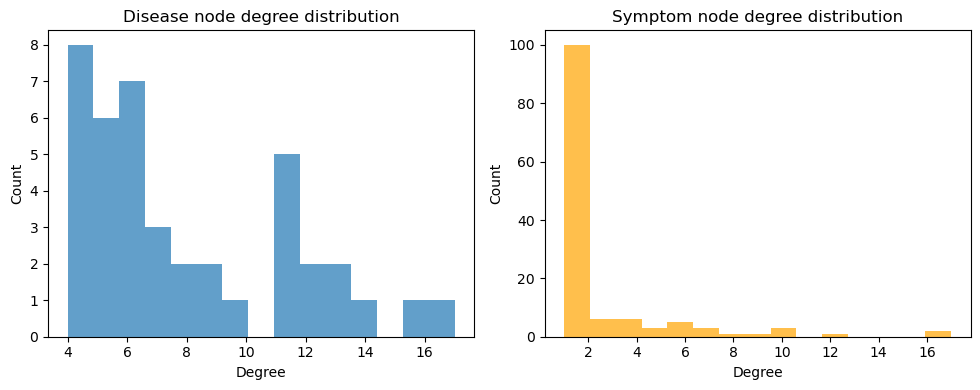

In [17]:
# 6. Summary statistics
print("Top 5 diseases by degree:", sorted(disease_degree.items(), key=lambda x: -x[1])[:5])
print("Top 5 symptoms by degree:", sorted(symptom_degree.items(), key=lambda x: -x[1])[:5])
print("Top 5 diseases by weighted degree:", sorted(disease_wdegree.items(), key=lambda x: -x[1])[:5])
print("Top 5 symptoms by weighted degree:", sorted(symptom_wdegree.items(), key=lambda x: -x[1])[:5])
print("Top 5 nodes by betweenness:", sorted(betweenness.items(), key=lambda x: -x[1])[:5])
print("Top 5 nodes by eigenvector centrality:", sorted(eigenvector.items(), key=lambda x: -x[1])[:5])
print("Number of connected components:", num_components)

# 7. plot degree distribution for diseases and symptoms
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.hist(list(disease_degree.values()), bins=15, alpha=0.7)
plt.title('Disease node degree distribution')
plt.xlabel('Degree')
plt.ylabel('Count')

plt.subplot(1,2,2)
plt.hist(list(symptom_degree.values()), bins=15, alpha=0.7, color='orange')
plt.title('Symptom node degree distribution')
plt.xlabel('Degree')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

# Increase in the number of components

## find best treshold 

In [18]:
edge_data.sort_values("weight", ascending=False).head(15)


,disease,symptom,weight,frequency,kappa
78,Paralysis (brain hemorrhage),altered_sensorium,0.695318,114,0.391
309,Urinary tract infection,continuous_feel_of_urine,0.695318,114,0.391
308,Urinary tract infection,bladder_discomfort,0.695318,114,0.391
3,Fungal infection,nodal_skin_eruptions,0.689080,108,0.378
4,Allergy,watering_from_eyes,0.689080,108,0.378
6,Allergy,shivering,0.689080,108,0.378
1,Fungal infection,dischromic _patches,0.689080,108,0.378
305,Acne,blackheads,0.660455,108,0.374
46,Gastroenteritis,sunken_eyes,0.660455,108,0.374
35,AIDS,extra_marital_contacts,0.660455,108,0.374


## apply treshold

In [19]:
threshold = 0.65
strong_edges = [(u, v) for u, v, attr in B.edges(data=True) if attr['weight'] > threshold]
B_strong = B.edge_subgraph(strong_edges).copy()
print("Strong edges (weight >", threshold, "):", len(strong_edges))
print("Number of connected components (strong subgraph):", nx.number_connected_components(B_strong))


Strong edges (weight > 0.65 ): 25
Number of connected components (strong subgraph): 11


## List of vertices in each cluster

In [20]:
for i, comp in enumerate(nx.connected_components(B_strong), 1):
    print(f"Component {i}: {comp}")


Component 1: {'Arthritis', 'movement_stiffness'}
Component 2: {'sunken_eyes', 'Gastroenteritis', 'dehydration'}
Component 3: {'Paralysis (brain hemorrhage)', 'altered_sensorium', 'weakness_of_one_body_side'}
Component 4: {'muscle_wasting', 'patches_in_throat', 'extra_marital_contacts', 'AIDS'}
Component 5: {'dischromic _patches', 'Fungal infection', 'nodal_skin_eruptions'}
Component 6: {'pain_in_anal_region', 'pain_during_bowel_movements', 'irritation_in_anus', 'Dimorphic hemmorhoids(piles)', 'bloody_stool'}
Component 7: {'watering_from_eyes', 'Allergy', 'shivering'}
Component 8: {'Urinary tract infection', 'continuous_feel_of_urine', 'bladder_discomfort'}
Component 9: {'yellow_crust_ooze', 'blister', 'red_sore_around_nose', 'Impetigo'}
Component 10: {'Hypertension', 'lack_of_concentration'}
Component 11: {'blackheads', 'pus_filled_pimples', 'scurring', 'Acne'}


## import to gephi

In [21]:

community_dict = {}
for i, comp in enumerate(nx.connected_components(B_strong), 1):
    for node in comp:
        community_dict[node] = i

#  community 
nx.set_node_attributes(B_strong, community_dict, 'community')

#  Gephi
nx.write_gexf(B_strong, "strong_subgraph_communities.gexf")


# Summary of Workflow Phase 1:

Summary of Workflow:

The raw patient dataset was cleaned and transformed into a bipartite disease–symptom network using Python.

Each edge between a disease and a symptom was weighted by a combination of normalized frequency and the Kappa coefficient, reflecting both occurrence and statistical association.

The resulting weighted bipartite graph was analyzed for basic network properties such as degree, weighted degree, betweenness, and eigenvector centrality.

Key nodes (diseases and symptoms) with the highest centralities were identified as potential diagnostic hubs.

Edge weight distribution was explored to identify a suitable threshold for filtering strong relationships.

By removing weak edges (weight ≤ 0.65), the network was split into 11 distinct connected components (communities).

Each community represented a disease and its most specific symptoms, highlighting strong diagnostic patterns.

The final network (with community labels) was exported to Gephi for visualization and further structural analysis.

# Phase 3: Disease–disease graph projection

Transform the disease–symptom bipartite graph into a disease-only graph. Each node represents a disease, and the edge weights are defined using similarity between symptom sets.

## create a disease–symptom matrix

In [22]:
# 1. Create a mapping: disease -> set of symptoms
disease_symptom_map = {}
for disease in disease_list:
    # All symptoms for this disease (across all rows)
    symptoms = set()
    disease_rows = df[df['Disease'] == disease]
    for col in symptom_cols:
        symptoms.update(disease_rows[col].astype(str).str.strip())
def clean_symptom(s):
    
    return str(s).strip().lower().replace(' ', '').replace('_', '')

disease_symptom_map = {}
for disease in disease_list:
    symptoms = set()
    disease_rows = df[df['Disease'] == disease]
    for col in symptom_cols:
        symptoms.update([clean_symptom(x) for x in disease_rows[col]])
    symptoms.discard('0')
    symptoms.discard('')
    symptoms.discard('nan')
    disease_symptom_map[disease] = symptoms

# Display a sample
for k, v in list(disease_symptom_map.items())[:5]:
    print(f"{k}: {v}")


Fungal infection: {'dischromicpatches', 'skinrash', 'nodalskineruptions', 'itching'}
Allergy: {'continuoussneezing', 'chills', 'shivering', 'wateringfromeyes'}
GERD: {'stomachpain', 'cough', 'vomiting', 'chestpain', 'ulcersontongue', 'acidity'}
Chronic cholestasis: {'nausea', 'yellowishskin', 'yellowingofeyes', 'vomiting', 'abdominalpain', 'itching', 'lossofappetite'}
Drug Reaction: {'stomachpain', 'skinrash', 'burningmicturition', 'spottingurination', 'itching'}


## Jaccard similarity calculation and construction of a disease–disease graph

In [23]:
# 1. Create an empty disease–disease graph
G_disease = nx.Graph()
G_disease.add_nodes_from(disease_list)

In [24]:
# 2. Compute Jaccard similarity for each pair of diseases
from itertools import combinations

for d1, d2 in combinations(disease_list, 2):
    s1 = disease_symptom_map[d1]
    s2 = disease_symptom_map[d2]
    if len(s1) == 0 and len(s2) == 0:
        continue
    intersection = len(s1 & s2)
    union = len(s1 | s2)
    if union == 0:
        jaccard = 0
    else:
        jaccard = intersection / union
    if jaccard > 0:
        G_disease.add_edge(d1, d2, weight=jaccard)
print("Disease–disease graph created! #nodes:", G_disease.number_of_nodes(), ", #edges:", G_disease.number_of_edges())       

Disease–disease graph created! #nodes: 41 , #edges: 380


In [25]:
#  Preview top 10 strongest similarities
edges_sorted = sorted(G_disease.edges(data=True), key=lambda x: -x[2]['weight'])[:10]
for u, v, attr in edges_sorted:
    print(f"{u} - {v}: Jaccard={attr['weight']:.3f}")

Hepatitis D - Hepatitis E: Jaccard=0.692
hepatitis A - Hepatitis D: Jaccard=0.667
Chronic cholestasis - Hepatitis D: Jaccard=0.600
Chronic cholestasis - hepatitis A: Jaccard=0.500
hepatitis A - Hepatitis E: Jaccard=0.500
Hepatitis C - Hepatitis D: Jaccard=0.500
Tuberculosis - Pneumonia: Jaccard=0.500
Malaria - Typhoid: Jaccard=0.462
Chronic cholestasis - Hepatitis C: Jaccard=0.444
Chronic cholestasis - Hepatitis E: Jaccard=0.429


In [26]:
# Export the disease–disease graph to GEXF format for Gephi
nx.write_gexf(G_disease, "disease_disease_graph.gexf")

# Phase 4: Discovering similar diseases

Explore groups of diseases with overlapping symptoms using network analysis, with potential relevance to exploratory differential-diagnosis research.

## community detection (disease graph)

In [27]:
import community as community_louvain
import random
random.seed(50)
np.random.seed(50)
# Run Louvain community detection
partition = community_louvain.best_partition(G_disease, weight='weight')

In [28]:

#  (community) 
num_communities = len(set(partition.values()))
print("Number of communities (Louvain):", num_communities)

# list of communities
from collections import defaultdict
communities = defaultdict(list)
for node, comm_id in partition.items():
    communities[comm_id].append(node)

for comm_id, members in communities.items():
    print(f"Community {comm_id+1}: {members}")


Number of communities (Louvain): 4
Community 2: ['Fungal infection', 'Allergy', 'Drug Reaction', 'AIDS', 'Bronchial Asthma', 'Chicken pox', 'Dengue', 'Tuberculosis', 'Common Cold', 'Pneumonia', 'Acne', 'Urinary tract infection', 'Psoriasis', 'Impetigo']
Community 3: ['GERD', 'Gastroenteritis', 'Hypertension', 'Migraine', 'Cervical spondylosis', 'Paralysis (brain hemorrhage)', 'Malaria', 'Typhoid', 'Dimorphic hemmorhoids(piles)', 'Heart attack', 'Hypoglycemia', '(vertigo) Paroymsal  Positional Vertigo']
Community 4: ['Chronic cholestasis', 'Peptic ulcer diseae', 'Jaundice', 'hepatitis A', 'Hepatitis B', 'Hepatitis C', 'Hepatitis D', 'Hepatitis E', 'Alcoholic hepatitis']
Community 1: ['Diabetes', 'Varicose veins', 'Hypothyroidism', 'Hyperthyroidism', 'Osteoarthristis', 'Arthritis']


# Phase 5: Symptom–symptom graph projection

Transform the disease–symptom bipartite graph into a symptom-only network. Each node represents a symptom, with edge weights defined using co-occurrence or similarity.

##  Create symptom list

In [29]:
# 1. Create symptom list from bipartite graph (B)
symptom_nodes = [n for n, d in B.nodes(data=True) if d['bipartite'] == 'symptom']

## Initialize symptom-symptom graph

In [30]:
#2.
G_symptom = nx.Graph()
G_symptom.add_nodes_from(symptom_nodes)

## Count co-occurrence of symptoms

In [31]:
# 3. Count co-occurrence of symptoms
co_occurrence = defaultdict(int)

for disease in [n for n, d in B.nodes(data=True) if d['bipartite'] == 'disease']:
    # Get symptoms connected to this disease
    connected_symptoms = list(B.neighbors(disease))
    # For every pair of symptoms in this disease, increase co-occurrence count
    for s1, s2 in combinations(connected_symptoms, 2):
        if s1 != s2:
            co_occurrence[tuple(sorted([s1, s2]))] += 1

## Add edges with weights

In [32]:
# 4. Add edges with weights
for (s1, s2), weight in co_occurrence.items():
    G_symptom.add_edge(s1, s2, weight=weight)

print(f"Symptom–symptom graph created! #nodes={G_symptom.number_of_nodes()}, #edges={G_symptom.number_of_edges()}")

Symptom–symptom graph created! #nodes=131, #edges=944


In [33]:
#  Preview strongest co-occurrences
edges_sorted = sorted(G_symptom.edges(data=True), key=lambda x: -x[2]['weight'])[:10]
for u, v, attr in edges_sorted:
    print(f"{u} - {v}: Co-occurrence weight={attr['weight']}")

vomiting - nausea: Co-occurrence weight=9
high_fever - fatigue: Co-occurrence weight=9
vomiting - abdominal_pain: Co-occurrence weight=8
loss_of_appetite - vomiting: Co-occurrence weight=7
loss_of_appetite - yellowing_of_eyes: Co-occurrence weight=7
loss_of_appetite - fatigue: Co-occurrence weight=7
vomiting - fatigue: Co-occurrence weight=7
yellowish_skin - abdominal_pain: Co-occurrence weight=7
loss_of_appetite - yellowish_skin: Co-occurrence weight=6
loss_of_appetite - abdominal_pain: Co-occurrence weight=6


In [34]:
# Write to GEXF (recommended for Gephi)
nx.write_gexf(G_symptom, "symptom_symptom_graph.gexf")


# Phase 6: Symptom co-occurrence network analysis

Analyze relationships among symptoms in the projected symptom–symptom network.

# Symptom centrality & rarity analysis

In [35]:
# ========= Symptom centrality & rarity analysis =========
# Assumptions:
# - G_symptom : symptom–symptom graph with edge attribute 'weight'
# - B         : original bipartite graph (disease <-> symptom) with node attribute 'bipartite'
# --------------------------------------------------------

## centrality

In [36]:
# 1) Compute centrality measures on the symptom–symptom graph
# -----------------------------------------------------------
# Degree (unweighted) and Strength (weighted degree)
deg = dict(G_symptom.degree())
wdeg = dict(G_symptom.degree(weight='weight'))

In [37]:
# Betweenness and Eigenvector centralities (use weights)
bet = nx.betweenness_centrality(G_symptom, weight='weight', normalized=True)
eig = nx.eigenvector_centrality(G_symptom, weight='weight', max_iter=1000)

In [38]:
# 2) Pack into a DataFrame for easy sorting/filtering
# ---------------------------------------------------
sym_df = pd.DataFrame({
    'symptom': list(G_symptom.nodes()),
    'degree': [deg[s] for s in G_symptom.nodes()],
    'weighted_degree': [wdeg[s] for s in G_symptom.nodes()],
    'betweenness': [bet[s] for s in G_symptom.nodes()],
    'eigenvector': [eig[s] for s in G_symptom.nodes()],
}).sort_values(['weighted_degree','degree'], ascending=False).reset_index(drop=True)

## most common sypmtoms

In [39]:
# 3) Show top-k "key" symptoms by multiple metrics
# ------------------------------------------------
k = 10
print("Top symptoms by weighted degree (strength):")
print(sym_df.sort_values('weighted_degree', ascending=False).head(k)[['symptom','weighted_degree']])

print("\nTop symptoms by betweenness:")
print(sym_df.sort_values('betweenness', ascending=False).head(k)[['symptom','betweenness']])

print("\nTop symptoms by eigenvector centrality:")
print(sym_df.sort_values('eigenvector', ascending=False).head(k)[['symptom','eigenvector']])

Top symptoms by weighted degree (strength):
             symptom  weighted_degree
0            fatigue              170
1           vomiting              129
2         high_fever              112
3   loss_of_appetite               95
4           headache               87
5             nausea               87
6            malaise               75
7     abdominal_pain               75
8             chills               74
9  yellowing_of_eyes               67

Top symptoms by betweenness:
                symptom  betweenness
18            skin_rash     0.151758
0               fatigue     0.130415
1              vomiting     0.122913
17             lethargy     0.082141
4              headache     0.081880
2            high_fever     0.078316
47         constipation     0.063486
13           joint_pain     0.062083
81  burning_micturition     0.045581
8                chills     0.039047

Top symptoms by eigenvector centrality:
              symptom  eigenvector
0             fatigue    

## low-degree symptoms (potentially rare)

In [40]:
low_deg_thr = 3   # you can change threshold (e.g., 1 or 2)
rare_symptoms = [s for s, d in deg.items() if d <= low_deg_thr]

print(f"\nLow-degree symptoms (degree <= {low_deg_thr}):", len(rare_symptoms))

# Build symptom -> diseases map from bipartite graph B
sym_to_dis = defaultdict(set)
for s in [n for n, d in B.nodes(data=True) if d.get('bipartite') == 'symptom']:
    for dis in B.neighbors(s):
        sym_to_dis[s].add(dis)


Low-degree symptoms (degree <= 3): 17


In [41]:
# Prepare a small table for rare symptoms: how many diseases and which?
rare_rows = []
for s in rare_symptoms:
    diseases_here = sorted(list(sym_to_dis.get(s, [])))
    rare_rows.append({
        'symptom': s,
        'degree': deg.get(s, 0),
        'weighted_degree': wdeg.get(s, 0.0),
        'num_diseases': len(diseases_here),
        'diseases': ", ".join(diseases_here[:6]) + (" ..." if len(diseases_here) > 6 else "")
    })

rare_df = pd.DataFrame(rare_rows).sort_values(['degree','weighted_degree']).reset_index(drop=True)
print("\nSample of low-degree symptoms (potentially rare):")
print(rare_df.head(17))


Sample of low-degree symptoms (potentially rare):
                      symptom  degree  weighted_degree  num_diseases  \
0           patches_in_throat       3                3             1   
1          watering_from_eyes       3                3             1   
2                 sunken_eyes       3                3             1   
3         dischromic _patches       3                3             1   
4                 dehydration       3                3             1   
5         foul_smell_of urine       3                3             1   
6          pus_filled_pimples       3                3             1   
7   weakness_of_one_body_side       3                3             1   
8                   shivering       3                3             1   
9                    scurring       3                3             1   
10                 blackheads       3                3             1   
11         bladder_discomfort       3                3             1   
12          a

In [42]:
# 5)Attach metrics to nodes for Gephi coloring/filtering
# -----------------------------------------------------------------
nx.set_node_attributes(G_symptom, deg, 'degree')
nx.set_node_attributes(G_symptom, wdeg, 'weighted_degree')
nx.set_node_attributes(G_symptom, bet, 'betweenness')
nx.set_node_attributes(G_symptom, eig, 'eigenvector')
nx.write_gexf(G_symptom, "symptom_symptom_with_centralities.gexf")

In [43]:
# Quick sanity checks 
n_total = len(df)                       # total rows
n_diseases = df['Disease'].nunique()    # number of distinct diseases
minmax = df['Disease'].value_counts().agg(['min','max','mean'])

print("Total rows:", n_total)
print("Unique diseases:", n_diseases)
print("Per-disease counts ->", minmax.to_dict())
print("Is perfectly balanced?", minmax['min']==minmax['max'])


Total rows: 4920
Unique diseases: 41
Per-disease counts -> {'min': 120.0, 'max': 120.0, 'mean': 120.0}
Is perfectly balanced? True


# Correlation analysis of symptoms

## Create a  graph for symptom–symptom with Jaccard weights

In [44]:
# ============================================
# Build Jaccard-based Symptom–Symptom graph
# ============================================

# 1) Collect symptom nodes from the bipartite graph B
symptoms = [n for n, d in B.nodes(data=True) if d.get('bipartite') == 'symptom']

# 2) Build symptom -> set of diseases mapping (neighbors in B)
sym_to_dis = {s: set(B.neighbors(s)) for s in symptoms}

# 3) Create an empty graph for symptom–symptom with Jaccard weights
G_symptom_jacc = nx.Graph()
G_symptom_jacc.add_nodes_from(symptoms)

# 4) Compute Jaccard for each pair of symptoms
def jaccard_sets(a: set, b: set) -> float:
    """Return Jaccard similarity of two sets."""
    if not a and not b:
        return 0.0
    inter = len(a & b)
    union = len(a | b)
    return 0.0 if union == 0 else inter / union

for s1, s2 in combinations(symptoms, 2):
    j = jaccard_sets(sym_to_dis[s1], sym_to_dis[s2])
    if j > 0.2:  # keep only pairs with nonzero similarity
        G_symptom_jacc.add_edge(s1, s2, weight=j)

print(f"Jaccard symptom–symptom graph: #nodes={G_symptom_jacc.number_of_nodes()}, #edges={G_symptom_jacc.number_of_edges()}")

Jaccard symptom–symptom graph: #nodes=131, #edges=418


## strongest pairs (strong correlation)

In [45]:
# 5) Show top-k strongest pairs by Jaccard
k = 15
top_pairs = sorted(G_symptom_jacc.edges(data=True), key=lambda e: -e[2]['weight'])[:k]
print("\nTop symptom pairs by Jaccard similarity:")
for u, v, attr in top_pairs:
    print(f"{u}  —  {v}:  Jaccard={attr['weight']:.3f}")


Top symptom pairs by Jaccard similarity:
internal_itching  —  passage_of_gases:  Jaccard=1.000
patches_in_throat  —  muscle_wasting:  Jaccard=1.000
patches_in_throat  —  extra_marital_contacts:  Jaccard=1.000
watering_from_eyes  —  shivering:  Jaccard=1.000
receiving_blood_transfusion  —  yellow_urine:  Jaccard=1.000
receiving_blood_transfusion  —  receiving_unsterile_injections:  Jaccard=1.000
sunken_eyes  —  dehydration:  Jaccard=1.000
cold_hands_and_feets  —  enlarged_thyroid:  Jaccard=1.000
cold_hands_and_feets  —  weight_gain:  Jaccard=1.000
cold_hands_and_feets  —  puffy_face_and_eyes:  Jaccard=1.000
cold_hands_and_feets  —  swollen_extremeties:  Jaccard=1.000
cold_hands_and_feets  —  brittle_nails:  Jaccard=1.000
anxiety  —  drying_and_tingling_lips:  Jaccard=1.000
anxiety  —  palpitations:  Jaccard=1.000
anxiety  —  slurred_speech:  Jaccard=1.000


# Community detection on Symptom–Symptom graph

## Method : Louvain 

In [46]:
# 1) Choose the symptom graph
#    If you built a Jaccard-weighted graph, use it; otherwise use the raw co-occurrence graph.
G = G_symptom_jacc   # or: G = G_symptom

# 2) Fix randomness for reproducibility
random.seed(50)
np.random.seed(50)

# 3) Run Louvain using edge weights
partition = community_louvain.best_partition(G, weight='weight')

# 4) Summary: number of communities
num_communities = len(set(partition.values()))
print("Number of communities (Louvain):", num_communities)

# 5) Group nodes by community id (for display)
communities = defaultdict(list)
for node, cid in partition.items():
    communities[cid].append(node)

# 6) Preview the first few communities
for cid, members in communities.items():
    sample = ", ".join(members[:12]) + (" ..." if len(members) > 12 else "")
    print(f"Community {cid+1} (size={len(members)}): {sample}")

# 7) Attach community id to nodes (useful for Gephi coloring/filtering)
nx.set_node_attributes(G, partition, "community")


Number of communities (Louvain): 18
Community 1 (size=17): stiff_neck, red_spots_over_body, muscle_weakness, loss_of_balance, swelling_joints, skin_rash, unsteadiness, movement_stiffness, weakness_in_limbs, spinning_movements, knee_pain, lack_of_concentration ...
Community 2 (size=12): depression, irritability, cold_hands_and_feets, enlarged_thyroid, mood_swings, weight_gain, dizziness, abnormal_menstruation, puffy_face_and_eyes, swollen_extremeties, brittle_nails, lethargy
Community 3 (size=12): internal_itching, ulcers_on_tongue, indigestion, burning_micturition, foul_smell_of urine, passage_of_gases, bladder_discomfort, stomach_pain, acidity, continuous_feel_of_urine, spotting_ urination, visual_disturbances
Community 4 (size=27): itching, mucoid_sputum, loss_of_appetite, blood_in_sputum, vomiting, dark_urine, chills, fast_heart_rate, yellowish_skin, high_fever, mild_fever, chest_pain ...
Community 7 (size=3): patches_in_throat, muscle_wasting, extra_marital_contacts
Community 8 (si

In [47]:
#8) Export to Gephi
nx.write_gexf(G, "symptom_symptom_Louvain.gexf")

# Summary of Workflow Phase 5 & 6

Symptom–Symptom Graph: 
Load & clean data: standardize symptom strings , identify the Disease column and all Symptom* columns.
Build bipartite graph (B): diseases ↔ symptoms with edge attributes.
Project to symptom–symptom graph: connect two symptoms if they co-occur in at least one disease.
Weights: either raw co-occurrence counts or normalized Jaccard
Inspect strongest pairs: sort edges by weight and print top co-occurring / highest-Jaccard symptom pairs.
Centrality analysis: compute degree, weighted_degree (strength), betweenness, and eigenvector to find key symptoms.
Rare symptoms check: list low-degree nodes and map each to the number of diseases they appear in.
Community detection: run Louvain (with weight='weight', seeded for reproducibility) to cluster co-occurring symptom groups.
Anntate & export: attach metrics and community to nodes and  nx.write_gexf(...) for Gephi visualization


# Additional analyses

Explore the robustness of community-detection results and structural properties of the network.

We complemented modularity-based community detection (Louvain) with an embedding-based pipeline to test the robustness of symptom groupings. Node2Vec/DeepWalk learns a low-dimensional vector for each symptom by sampling random walks, thus encoding local–global proximity. Clustering these vectors with KMeans provides an algorithmically independent view of the mesoscale structure. Agreement between the two views strengthens the validity of the discovered clinical groupings.

In [52]:
# ========================= Node2Vec (DeepWalk-style) + KMeans on symptom graph =========================
# Requirements: networkx, numpy, scikit-learn, python-louvain, node2vec
# G should be your symptom–symptom graph (preferably Jaccard-weighted): e.g., G_symptom_jacc

!pip install -q node2vec==0.4.6 gensim==4.3.2
import random, numpy as np, networkx as nx
from collections import Counter, defaultdict


# ---- 0) Select graph ----
G = G_symptom_jacc   # or: G = G_symptom   (if you used raw co-occurrence)

# ---- 1) Reproducibility ----
SEED = 42
random.seed(SEED); np.random.seed(SEED)

# ---- 2) Louvain (for reference & number of communities) ----
import community as community_louvain
part_louvain = community_louvain.best_partition(G, weight='weight', random_state=SEED)
k_louvain = len(set(part_louvain.values()))
print(f"Louvain communities: {k_louvain}")

# ---- 3) Node2Vec embeddings (DeepWalk style with p=1, q=1) ----
# try to import node2vec; if not installed, instruct to install
try:
    from node2vec import Node2Vec
except Exception as e:
    raise ImportError("Please install node2vec first: pip install node2vec") from e

# Build the model (weights are read from edge attribute 'weight')
node2vec = Node2Vec(
    G,                 # graph
    dimensions=64,     # embedding size
    walk_length=80,    # per-walk length
    num_walks=10,      # walks per node
    p=1, q=1,          # p=q=1 => DeepWalk behavior; tune for Node2Vec bias
    workers=2,         # CPU workers
    weight_key='weight',
    seed=SEED
)

# Train skip-gram model
w2v_model = node2vec.fit(window=10, min_count=1, batch_words=256, epochs=1)

# Build embedding matrix aligned with node order
nodes = list(G.nodes())
X = np.vstack([w2v_model.wv[str(n)] if str(n) in w2v_model.wv else w2v_model.wv[n] for n in nodes])

# ---- 4) KMeans clustering on embeddings ----
from sklearn.cluster import KMeans

# Use Louvain's k as a starting point (you can change it or run a silhouette search)
k = k_louvain
kmeans = KMeans(n_clusters=k, n_init=20, random_state=SEED)
labels_km = kmeans.fit_predict(X)

# Map cluster labels back to node names
clust_kmeans = {node: int(lbl) for node, lbl in zip(nodes, labels_km)}

# ---- 5) Compare KMeans clusters vs. Louvain using NMI / ARI ----
from sklearn.metrics import normalized_mutual_info_score, adjusted_rand_score

# Align both labelings by node order
y_true = np.array([part_louvain[n] for n in nodes])   # Louvain IDs
y_pred = np.array([clust_kmeans[n] for n in nodes])   # KMeans IDs

nmi = normalized_mutual_info_score(y_true, y_pred)
ari = adjusted_rand_score(y_true, y_pred)
print(f"NMI(KMeans || Louvain) = {nmi:.3f}")
print(f"ARI(KMeans || Louvain) = {ari:.3f}")

# ---- 6) Quick summary of KMeans cluster sizes ----
sizes = Counter(labels_km)
print("KMeans cluster sizes:", dict(sorted(sizes.items())))

# Show first few clusters with sample members
by_cluster = defaultdict(list)
for n, c in clust_kmeans.items():
    by_cluster[c].append(n)
for cid, members in sorted(by_cluster.items())[:6]:
    sample = ", ".join(members[:12]) + (" ..." if len(members) > 12 else "")
    print(f"Cluster {cid}: size={len(members)} -> {sample}")


Louvain communities: 18


Computing transition probabilities:   0%|          | 0/131 [00:00<?, ?it/s]

NMI(KMeans || Louvain) = 0.853
ARI(KMeans || Louvain) = 0.583
KMeans cluster sizes: {0: 26, 1: 7, 2: 3, 3: 6, 4: 7, 5: 16, 6: 4, 7: 3, 8: 3, 9: 14, 10: 12, 11: 3, 12: 4, 13: 2, 14: 2, 15: 13, 16: 2, 17: 4}
Cluster 0: size=26 -> red_spots_over_body, mucoid_sputum, blood_in_sputum, watering_from_eyes, muscle_pain, redness_of_eyes, congestion, chills, loss_of_smell, fast_heart_rate, runny_nose, high_fever ...
Cluster 1: size=7 -> ulcers_on_tongue, burning_micturition, foul_smell_of urine, bladder_discomfort, stomach_pain, continuous_feel_of_urine, spotting_ urination
Cluster 2: size=3 -> red_sore_around_nose, blister, yellow_crust_ooze
Cluster 3: size=6 -> obesity, prominent_veins_on_calf, swollen_blood_vessels, cramps, bruising, swollen_legs
Cluster 4: size=7 -> pain_in_anal_region, pain_during_bowel_movements, irritation_in_anus, toxic_look_(typhos), belly_pain, bloody_stool, constipation
Cluster 5: size=16 -> stiff_neck, depression, internal_itching, muscle_weakness, cold_hands_and_fee

NMI = 0.853 (high) and ARI = 0.583 (moderate) → strong information overlap; most pairwise memberships also agree, with some merges/splits.

Cluster sizes were well-distributed ( {0:26, 1:7, 2:3, 3:6, 4:7, 5:16, …}).

Representative KMeans clusters (samples shown) align with clinically coherent sets identified earlier:

Respiratory/viral mix (Cluster 0): signs like congestion/runny_nose/loss_of_smell, chills, high_fever → consistent with common cold/allergic–viral patterns; includes exanthema features (red_spots_over_body) marking overlap with dengue-like presentations.

Urinary tract infection (Cluster 1): bladder_discomfort, burning_micturition, foul_smell_of_urine, continuous_feel_of_urine, etc. (compact, disease-specific).

Impetigo (Cluster 2): red_sore_around_nose, blister, yellow_crust_ooze (the classic triad).

Peripheral/venous (Cluster 3): swollen_legs, prominent_veins_on_calf, swollen_blood_vessels, cramps, bruising → varicose-vein/vascular picture.

Lower-GI / anorectal ± typhoid (Cluster 4): pain_in_anal_region, pain_during_bowel_movements, irritation_in_anus, bloody_stool, constipation, belly_pain, toxic_look_(typhos) → two close pathways useful for differential diagnosis.

Thyroid/hormonal (Cluster 5): cold_hands_and_feet, weight_gain, enlarged_thyroid, puffy_face_and_eyes, abnormal_menstruation, mood_swings, swollen_extremities → coherent endocrine cluster.

# extra

|D|=41, |S|=131
Disease degree stats: min= 4  max= 17  mean= 7.829268292682927
Symptom degree stats: min= 1  max= 17  mean= 2.450381679389313


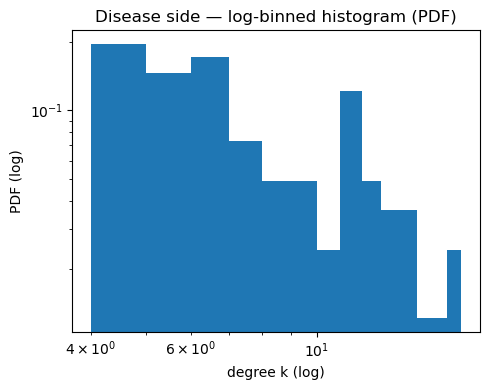

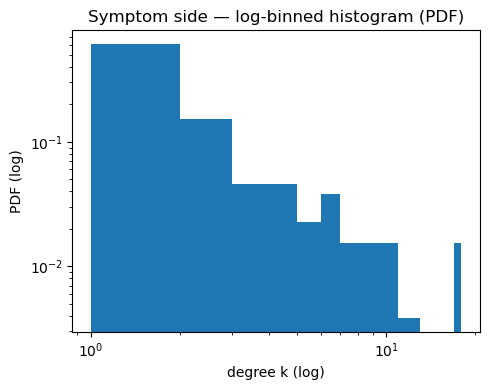

Installing 'powerlaw' ...
xmin progress: 91%
Disease degree — power-law fit:
  xmin = 11.0, alpha = 6.667, KS = 0.056, n_tail = 12 of 41
  Compare power_law vs            lognormal:  R=-0.159, p=0.641  -> favored: lognormal
  Compare power_law vs          exponential:  R=-0.179, p=0.499  -> favored: exponential


Assuming nested distributions


  Compare power_law vs  truncated_power_law:  R=-0.169, p=0.561  -> favored: truncated_power_law


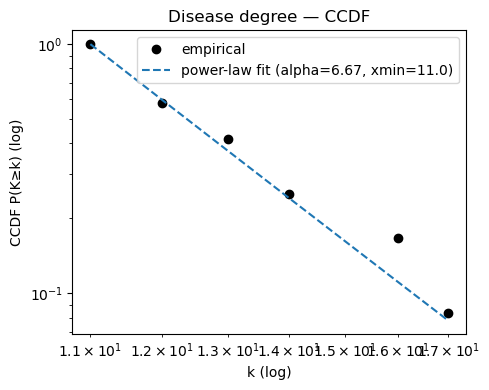

xmin progress: 90%
Symptom degree — power-law fit:
  xmin = 1.0, alpha = 1.826, KS = 0.068, n_tail = 131 of 131
  Compare power_law vs            lognormal:  R=-5.228, p=0.001  -> favored: lognormal
  Compare power_law vs          exponential:  R=+13.173, p=0.050  -> favored: power_law


Assuming nested distributions


  Compare power_law vs  truncated_power_law:  R=-6.028, p=0.001  -> favored: truncated_power_law


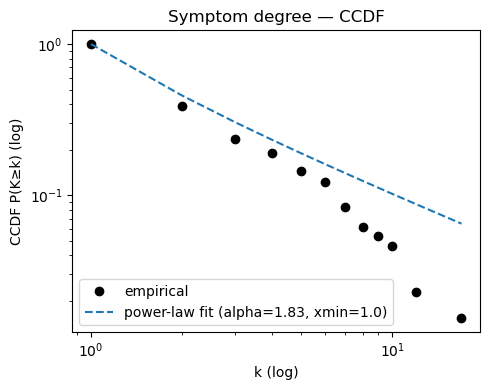

In [56]:
# ==================== Degree distribution + Power-law test on the bipartite graph B ====================
# Assumes: B is the Disease–Symptom bipartite graph with node attribute 'bipartite' in {'disease','symptom'}

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

# 0) Split nodes and get degree arrays (ignore zeros if any)
disease_nodes = [n for n, d in B.nodes(data=True) if d.get('bipartite') == 'disease']
symptom_nodes = [n for n, d in B.nodes(data=True) if d.get('bipartite') == 'symptom']

deg_dis = np.array([deg for _, deg in B.degree(disease_nodes)], dtype=int)
deg_sym = np.array([deg for _, deg in B.degree(symptom_nodes)], dtype=int)

print(f"|D|={len(disease_nodes)}, |S|={len(symptom_nodes)}")
print("Disease degree stats: min=",deg_dis.min()," max=",deg_dis.max()," mean=",deg_dis.mean())
print("Symptom degree stats: min=",deg_sym.min()," max=",deg_sym.max()," mean=",deg_sym.mean())

# 1) Plot log-binned histograms (PDF) for degree sequences
def plot_log_hist(deg, title):
    d = np.asarray(deg, dtype=int)
    d = d[d>0]
    # log-spaced integer bins
    b = np.unique(np.clip(np.floor(np.logspace(np.log10(d.min()), np.log10(d.max()), 15)), d.min(), d.max())).astype(int)
    # ensure strictly increasing and append last+1 for hist right edge
    b = np.unique(b)
    bins = np.r_[b, b[-1]+1]
    plt.figure(figsize=(5,4))
    plt.hist(d, bins=bins, density=True)
    plt.xscale("log"); plt.yscale("log")
    plt.xlabel("degree k (log)"); plt.ylabel("PDF (log)")
    plt.title(f"{title} — log-binned histogram (PDF)")
    plt.tight_layout()
    plt.show()

plot_log_hist(deg_dis, "Disease side")
plot_log_hist(deg_sym, "Symptom side")

# 2) CCDF + power-law fit using 'powerlaw'
try:
    import powerlaw
except ImportError:
    print("Installing 'powerlaw' ...")
    import sys, subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "powerlaw"])
    import powerlaw

def fit_and_plot_ccdf(deg, title):
    data = np.asarray(deg, dtype=int)
    data = data[data>0]
    # Fit discrete power-law; let the library choose xmin (via KS minimization)
    fit = powerlaw.Fit(data, discrete=True, verbose=False)
    xmin, alpha = fit.power_law.xmin, fit.power_law.alpha
    ks = fit.power_law.KS()
    print(f"\n{title} — power-law fit:")
    print(f"  xmin = {xmin}, alpha = {alpha:.3f}, KS = {ks:.3f}, n_tail = {np.sum(data>=xmin)} of {len(data)}")

    # Compare against alternatives
    for alt in ["lognormal", "exponential", "truncated_power_law"]:
        R, p = fit.distribution_compare('power_law', alt)
        fav = "power_law" if R>0 else alt
        print(f"  Compare power_law vs {alt:>20s}:  R={R:+.3f}, p={p:.3f}  -> favored: {fav}")

    # CCDF plot (empirical vs fitted power-law)
    fig = plt.figure(figsize=(5,4))
    ax = fig.add_subplot(111)
    fit.plot_ccdf(ax=ax, color="k", marker="o", linewidth=0.0, label="empirical")
    fit.power_law.plot_ccdf(ax=ax, linestyle="--", label=f"power-law fit (alpha={alpha:.2f}, xmin={xmin})")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("k (log)"); ax.set_ylabel("CCDF P(K≥k) (log)")
    ax.set_title(f"{title} — CCDF")
    ax.legend()
    plt.tight_layout(); plt.show()
    return fit

fit_dis = fit_and_plot_ccdf(deg_dis, "Disease degree")
fit_sym = fit_and_plot_ccdf(deg_sym, "Symptom degree")
